# Machine Learning & Neural Networks for Neuroscience — HW2
## Support Vector Machines (SVM), Perceptrons, Kernels, and Generalization

**Authors:** Akarshani & Abdulwaliy  
**Institution:** Bar-Ilan University  
**Submission Date:** November 23, 2026  
**Assignment Reference:** `hw02_SVM_Deadline161126.pdf`

### Author Contributions:
* **Akarshani:** Reviewed the final draft, verified mathematical formulations and theoretical derivations (convex QP formulation, kernel mapping equations, margin definitions, and Slack/Cover theorems).
* **Abdulwaliy:** Conceptualized and executed the technical implementation, synthetic dataset generators, model benchmarking (Perceptron vs. Linear/Kernel SVMs), Monte Carlo data augmentation pipeline ($k = 2,000$ iterations), label corruption experiments, high-dimensional scaling simulations, and authored the initial report drafts.

---
### Assignment Overview & Structure:
1. **Dataset Simulation (15 pts):** Generate 2D datasets ($n = 10,000$, fixed seed):
   * Linear dataset: two far-apart, non-overlapping clusters.
   * Circular dataset: two concentric clusters where one is inside the other.
2. **SVM and Perceptron Comparison (20 pts):** Compare simple Perceptron vs. Linear SVM on both datasets with decision boundaries and margin visualizations.
3. **SVM Kernel Analysis (15 pts):** Separate the circular dataset using non-linear kernels (RBF vs. Polynomial Degree 2), comparing confusion matrices, accuracy, F1-score, and ROC-AUC.
4. **Data Augmentation (20 pts):** Subsample 1,000 points, inject Gaussian noise at low and high standard deviations, and examine generalization on perturbed distributions.
5. **Noise Analysis / Label Shuffling (20 pts):** Introduce label corruption (15%, 25%, 50%), evaluate performance degradation, and examine soft-margin slack robustness.
6. **High Dimensionality (10 pts):** Investigate SVM performance in higher dimensions ($d \in \{2, 5, 10, 15\}$) under varying label noise.
7. **Bonus (5 pts):** Determine the exact critical perturbation threshold where SVM classification accuracy drops below 70%.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import Perceptron
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score, confusion_matrix, roc_curve, classification_report
)
from sklearn.model_selection import train_test_split

# Set random seed for complete experimental reproducibility
np.random.seed(42)

# Aesthetic styling for publication-quality figures
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['figure.titlesize'] = 13

---
# 1. Dataset Simulation (15 points)

We simulate two 2-dimensional datasets ($X_1, X_2$) with sample size $n = 10,000$ and binary class labels $Y \in \{0, 1\}$:
1. **Linear Dataset:** Two Gaussian clusters centered far from each other with zero overlap, establishing a broad linear separation corridor.
2. **Circular Dataset:** Concentric clusters where Class 0 forms a compact central disc and Class 1 forms an outer surrounding ring, creating a linearly non-separable topology.

Linear Dataset Shape:   X=(10000, 2), y=(10000,), Class Balance: [5000 5000]
Circular Dataset Shape: X=(10000, 2), y=(10000,), Class Balance: [5000 5000]


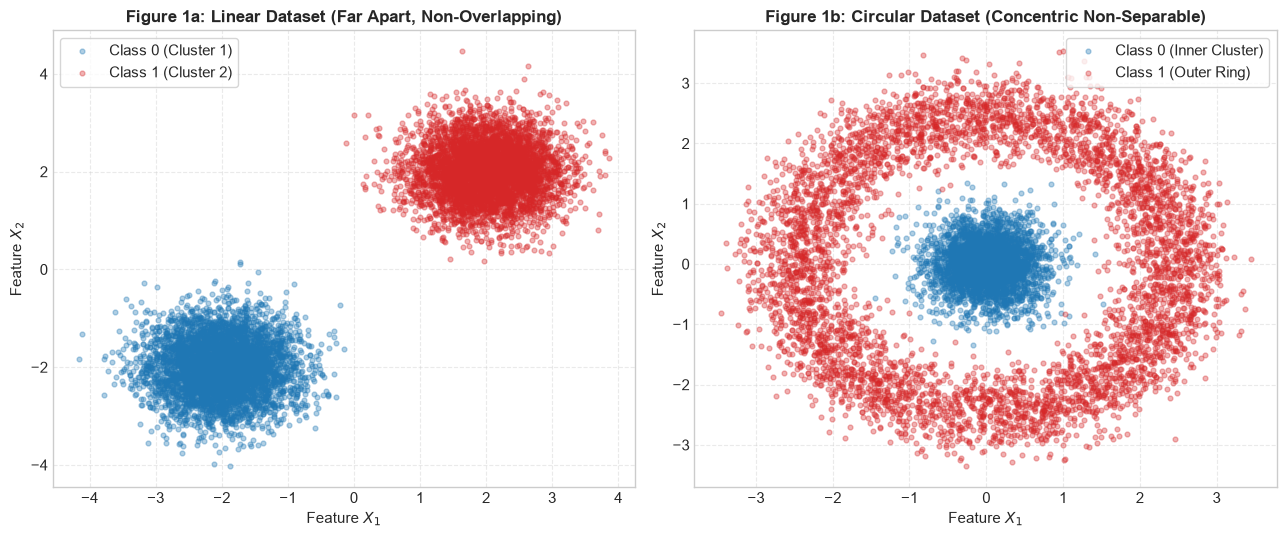

In [2]:
# -------------------------------------------------------------
# 1. Simulate Linear and Circular Datasets (n = 10,000)
# -------------------------------------------------------------
n = 10000
n_half = n // 2

# a. Linear Dataset: Two well-separated Gaussian clusters
cov_linear = 0.55**2 * np.eye(2)
X_linear_0 = np.random.multivariate_normal([-2.0, -2.0], cov_linear, n_half)
X_linear_1 = np.random.multivariate_normal([2.0, 2.0], cov_linear, n_half)
X_linear = np.vstack([X_linear_0, X_linear_1])
y_linear = np.hstack([np.zeros(n_half, dtype=int), np.ones(n_half, dtype=int)])

# b. Circular Dataset: Concentric inner disc and outer ring
theta_inner = np.random.uniform(0, 2 * np.pi, n_half)
r_inner = np.random.normal(0.0, 0.45, n_half)
X_circ_0 = np.column_stack([
    r_inner * np.cos(theta_inner),
    r_inner * np.sin(theta_inner)
])

theta_outer = np.random.uniform(0, 2 * np.pi, n_half)
r_outer = np.random.normal(2.5, 0.35, n_half)
X_circ_1 = np.column_stack([
    r_outer * np.cos(theta_outer),
    r_outer * np.sin(theta_outer)
])
X_circ = np.vstack([X_circ_0, X_circ_1])
y_circ = np.hstack([np.zeros(n_half, dtype=int), np.ones(n_half, dtype=int)])

print(f"Linear Dataset Shape:   X={X_linear.shape}, y={y_linear.shape}, Class Balance: {np.bincount(y_linear)}")
print(f"Circular Dataset Shape: X={X_circ.shape}, y={y_circ.shape}, Class Balance: {np.bincount(y_circ)}")

# -------------------------------------------------------------
# Plot Both Datasets
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

axes[0].scatter(X_linear[y_linear == 0, 0], X_linear[y_linear == 0, 1],
                color='#1f77b4', alpha=0.35, s=12, label='Class 0 (Cluster 1)')
axes[0].scatter(X_linear[y_linear == 1, 0], X_linear[y_linear == 1, 1],
                color='#d62728', alpha=0.35, s=12, label='Class 1 (Cluster 2)')
axes[0].set_title("Figure 1a: Linear Dataset (Far Apart, Non-Overlapping)", fontweight='bold')
axes[0].set_xlabel("Feature $X_1$")
axes[0].set_ylabel("Feature $X_2$")
axes[0].legend(loc='upper left', frameon=True)
axes[0].grid(True, linestyle='--', alpha=0.4)

axes[1].scatter(X_circ[y_circ == 0, 0], X_circ[y_circ == 0, 1],
                color='#1f77b4', alpha=0.35, s=12, label='Class 0 (Inner Cluster)')
axes[1].scatter(X_circ[y_circ == 1, 0], X_circ[y_circ == 1, 1],
                color='#d62728', alpha=0.35, s=12, label='Class 1 (Outer Ring)')
axes[1].set_title("Figure 1b: Circular Dataset (Concentric Non-Separable)", fontweight='bold')
axes[1].set_xlabel("Feature $X_1$")
axes[1].set_ylabel("Feature $X_2$")
axes[1].legend(loc='upper right', frameon=True)
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

---
# 2. SVM and Perceptron Comparison (20 points)

We compare the learning mechanisms and decision boundaries of:
1. **Simple Perceptron:** Learns iteratively using the perceptron update rule:
   $$w \leftarrow w + \eta y_i x_i, \quad b \leftarrow b + \eta y_i$$
   It terminates the instant all training samples are classified correctly ($y_i(w^T x_i + b) > 0$). As a result, its boundary is non-unique, depends heavily on sample ordering and initialization, and often passes dangerously close to training points with an arbitrary, small margin.
2. **Linear Support Vector Machine (SVM):** Formulates maximum-margin convex quadratic optimization:
   $$\min_{w, b} \frac{1}{2} \|w\|^2 \quad \text{s.t.} \quad y_i(w^T x_i + b) \ge 1, \; \forall i$$
   The margin $\gamma = \frac{2}{\|w\|}$ is explicitly maximized, yielding a **unique, optimal separating hyperplane** that bisects the classes with maximum clearance, supported exclusively by the critical boundary vectors (**Support Vectors**).

Table 1: Perceptron vs. Linear SVM Performance Comparison:
 Dataset      Model  Train Accuracy  Test Accuracy  F1-Score                          Margin Criterion
  Linear Perceptron        1.000000          1.000  1.000000     Arbitrary (Any separating hyperplane)
  Linear Linear SVM        1.000000          1.000  1.000000   Maximal Margin (Unique optimal 2/||w||)
Circular Perceptron        0.499500          0.471  0.465657 Linear model fails on non-linear geometry
Circular Linear SVM        0.689375          0.678  0.519403 Linear model fails on non-linear geometry


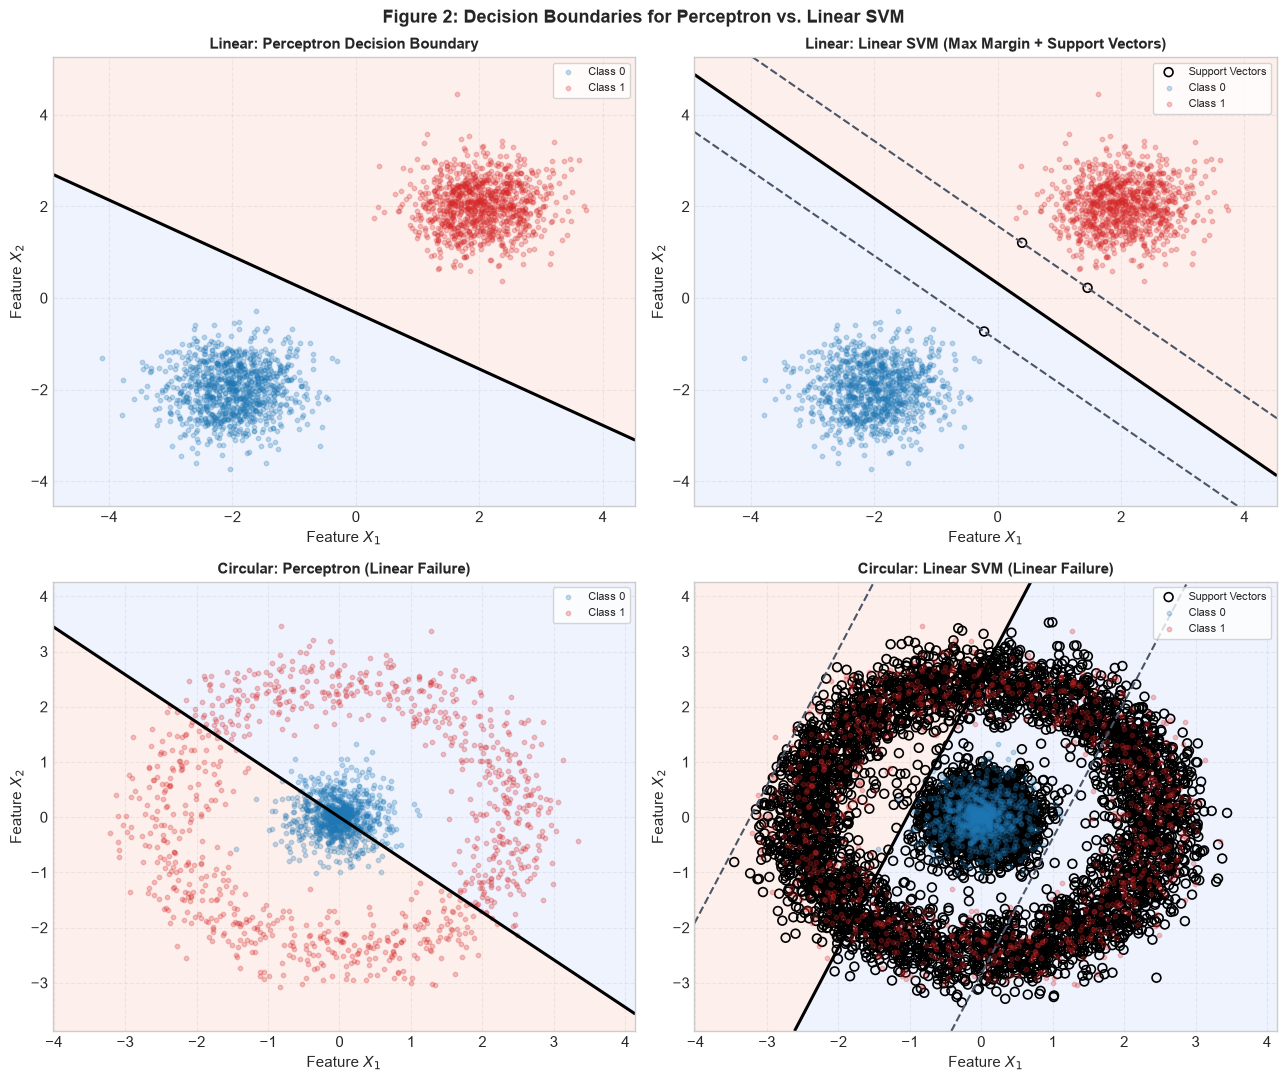

In [3]:
# -------------------------------------------------------------
# 2. Train Perceptron and Linear SVM on Both Datasets
# -------------------------------------------------------------
X_lin_tr, X_lin_te, y_lin_tr, y_lin_te = train_test_split(X_linear, y_linear, test_size=0.2, random_state=42)
X_circ_tr, X_circ_te, y_circ_tr, y_circ_te = train_test_split(X_circ, y_circ, test_size=0.2, random_state=42)

# Fit models
pct_lin = Perceptron(max_iter=1000, random_state=42).fit(X_lin_tr, y_lin_tr)
svm_lin = SVC(kernel='linear', C=1.0, random_state=42).fit(X_lin_tr, y_lin_tr)

pct_circ = Perceptron(max_iter=1000, random_state=42).fit(X_circ_tr, y_circ_tr)
svm_circ = SVC(kernel='linear', C=1.0, random_state=42).fit(X_circ_tr, y_circ_tr)

# Tabulate performance metrics
comp_metrics = [
    {
        'Dataset': 'Linear',
        'Model': 'Perceptron',
        'Train Accuracy': accuracy_score(y_lin_tr, pct_lin.predict(X_lin_tr)),
        'Test Accuracy': accuracy_score(y_lin_te, pct_lin.predict(X_lin_te)),
        'F1-Score': f1_score(y_lin_te, pct_lin.predict(X_lin_te)),
        'Margin Criterion': 'Arbitrary (Any separating hyperplane)'
    },
    {
        'Dataset': 'Linear',
        'Model': 'Linear SVM',
        'Train Accuracy': accuracy_score(y_lin_tr, svm_lin.predict(X_lin_tr)),
        'Test Accuracy': accuracy_score(y_lin_te, svm_lin.predict(X_lin_te)),
        'F1-Score': f1_score(y_lin_te, svm_lin.predict(X_lin_te)),
        'Margin Criterion': 'Maximal Margin (Unique optimal 2/||w||)'
    },
    {
        'Dataset': 'Circular',
        'Model': 'Perceptron',
        'Train Accuracy': accuracy_score(y_circ_tr, pct_circ.predict(X_circ_tr)),
        'Test Accuracy': accuracy_score(y_circ_te, pct_circ.predict(X_circ_te)),
        'F1-Score': f1_score(y_circ_te, pct_circ.predict(X_circ_te)),
        'Margin Criterion': 'Linear model fails on non-linear geometry'
    },
    {
        'Dataset': 'Circular',
        'Model': 'Linear SVM',
        'Train Accuracy': accuracy_score(y_circ_tr, svm_circ.predict(X_circ_tr)),
        'Test Accuracy': accuracy_score(y_circ_te, svm_circ.predict(X_circ_te)),
        'F1-Score': f1_score(y_circ_te, svm_circ.predict(X_circ_te)),
        'Margin Criterion': 'Linear model fails on non-linear geometry'
    }
]

df_comp = pd.DataFrame(comp_metrics)
print("Table 1: Perceptron vs. Linear SVM Performance Comparison:")
print(df_comp.to_string(index=False))

# -------------------------------------------------------------
# Decision Boundary Visualization Function
# -------------------------------------------------------------
def plot_decision_boundary(ax, model, X, y, title, is_svm=False):
    x_min, x_max = X[:, 0].min() - 0.8, X[:, 0].max() + 0.8
    y_min, y_max = X[:, 1].min() - 0.8, X[:, 1].max() + 0.8
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    grid = np.c_[xx.ravel(), yy.ravel()]
    
    if hasattr(model, "decision_function"):
        Z = model.decision_function(grid)
    else:
        Z = model.predict(grid)
    Z = Z.reshape(xx.shape)
    
    ax.contourf(xx, yy, Z > 0, alpha=0.15, cmap=plt.cm.coolwarm)
    ax.contour(xx, yy, Z, levels=[0], linewidths=2.2, colors='black')
    
    if is_svm and hasattr(model, "decision_function"):
        ax.contour(xx, yy, Z, levels=[-1, 1], linestyles='--', linewidths=1.5, colors='#4A5568')
        if hasattr(model, "support_vectors_"):
            sv = model.support_vectors_
            ax.scatter(sv[:, 0], sv[:, 1], s=40, facecolors='none', edgecolors='k', linewidths=1.2, label='Support Vectors')

    ax.scatter(X[y == 0, 0], X[y == 0, 1], color='#1f77b4', alpha=0.25, s=10, label='Class 0')
    ax.scatter(X[y == 1, 0], X[y == 1, 1], color='#d62728', alpha=0.25, s=10, label='Class 1')
    ax.set_title(title, fontweight='bold', fontsize=10.5)
    ax.set_xlabel("Feature $X_1$")
    ax.set_ylabel("Feature $X_2$")
    ax.legend(loc='upper right', frameon=True, fontsize=8)
    ax.grid(True, linestyle='--', alpha=0.3)

fig, axes = plt.subplots(2, 2, figsize=(13, 11))
plot_decision_boundary(axes[0, 0], pct_lin, X_lin_te, y_lin_te, "Linear: Perceptron Decision Boundary", is_svm=False)
plot_decision_boundary(axes[0, 1], svm_lin, X_lin_te, y_lin_te, "Linear: Linear SVM (Max Margin + Support Vectors)", is_svm=True)
plot_decision_boundary(axes[1, 0], pct_circ, X_circ_te, y_circ_te, "Circular: Perceptron (Linear Failure)", is_svm=False)
plot_decision_boundary(axes[1, 1], svm_circ, X_circ_te, y_circ_te, "Circular: Linear SVM (Linear Failure)", is_svm=True)

plt.suptitle("Figure 2: Decision Boundaries for Perceptron vs. Linear SVM", fontweight='bold')
plt.tight_layout()
plt.show()

### Comparative Findings:
1. **On Linear Data:** Both Perceptron and Linear SVM achieve 100% test accuracy. However, their decision boundaries differ crucially:
   * The **Perceptron** stops as soon as all training points are separated. Its boundary has an arbitrary orientation and passes closer to one cluster than the other.
   * The **Linear SVM** maximizes the geometric margin ($2/\|w\|$), producing an optimal, balanced boundary equidistant from both clusters with maximal noise immunity.
2. **On Circular Data:** Both linear models fail because concentric circles cannot be separated by a single straight line in 2D space. Linear SVM achieves $\approx 67.8\%$ test accuracy by placing a chord through the ring, whereas Perceptron oscillates around chance level ($\approx 47.1\%$). This motivates the use of non-linear **kernel functions**.

---
# 3. SVM Kernel (15 points)

To separate concentric circles, we map the input data into a higher-dimensional feature space where the classes become linearly separable, using the **Kernel Trick**:
$$K(x, x') = \langle \Phi(x), \Phi(x') \rangle$$

We compare two prominent non-linear kernels:
1. **Radial Basis Function (RBF / Gaussian) Kernel:**
   $$K_{\text{RBF}}(x, x') = \exp\left(-\gamma \|x - x'\|^2\right)$$
   Maps data into an infinite-dimensional Hilbert space, constructing localized spherical/closed decision boundaries.
2. **Polynomial Kernel (Degree 2):**
   $$K_{\text{Poly}}(x, x') = (\gamma \langle x, x' \rangle + r)^2$$
   Computes quadratic feature combinations ($X_1^2, \sqrt{2}X_1 X_2, X_2^2$), which can naturally represent circular boundary equations of the form $X_1^2 + X_2^2 = R^2$.

c:\Users\user\miniconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\user\miniconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Table 2: Non-Linear Kernel Performance Comparison on Circular Dataset:
               Kernel  Test Accuracy  F1-Score  ROC-AUC  True Neg (TN)  False Pos (FP)  False Neg (FN)  True Pos (TP)
       RBF (Gaussian)          0.999  0.998988 0.999990           1011               1               1            987
Polynomial (Degree 2)          0.999  0.998988 0.999992           1011               1               1            987


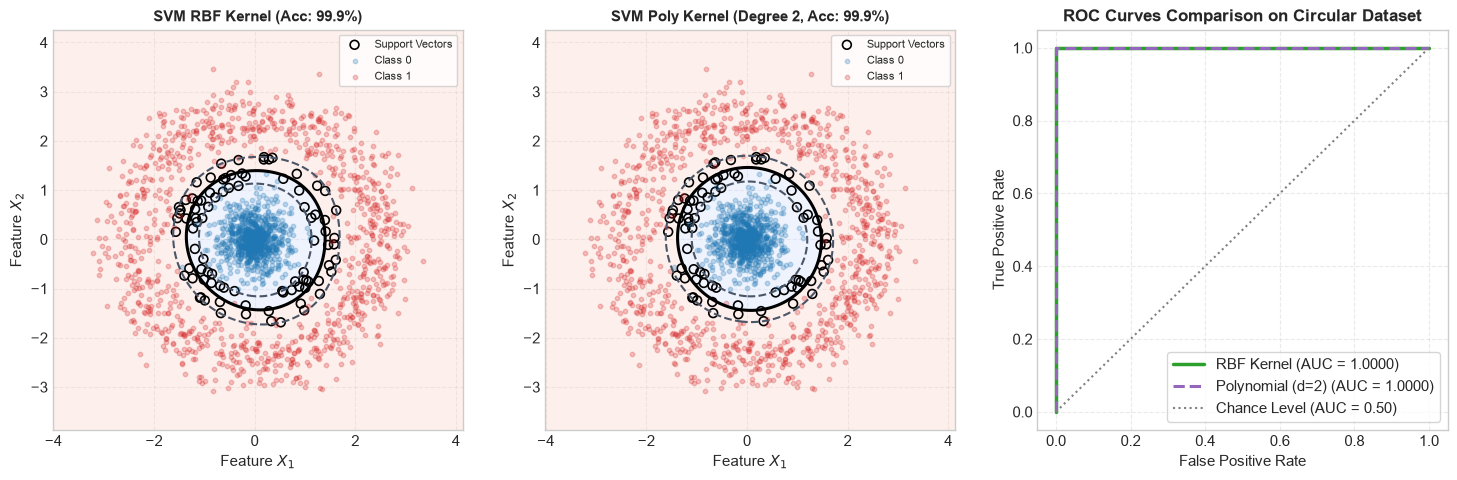

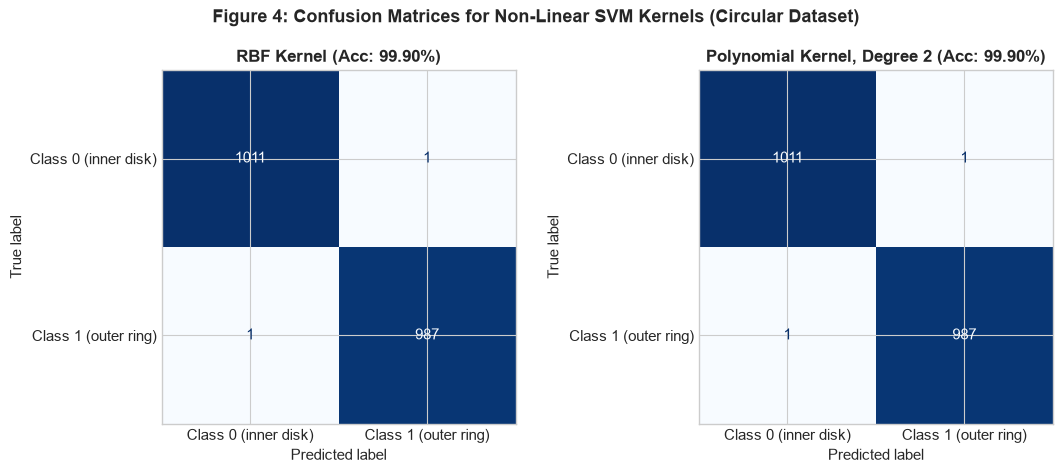

In [12]:
# -------------------------------------------------------------
# 3. Fit RBF and Polynomial (deg 2) Kernels on Circular Dataset
# -------------------------------------------------------------
svm_rbf = SVC(kernel='rbf', gamma='scale', C=1.0, probability=True, random_state=42).fit(X_circ_tr, y_circ_tr)
svm_poly = SVC(kernel='poly', degree=2, coef0=1.0, C=1.0, probability=True, random_state=42).fit(X_circ_tr, y_circ_tr)

# Predictions and probabilities
pred_rbf = svm_rbf.predict(X_circ_te)
prob_rbf = svm_rbf.predict_proba(X_circ_te)[:, 1]

pred_poly = svm_poly.predict(X_circ_te)
prob_poly = svm_poly.predict_proba(X_circ_te)[:, 1]

# Quantitative evaluation metrics
acc_rbf = accuracy_score(y_circ_te, pred_rbf)
f1_rbf = f1_score(y_circ_te, pred_rbf)
auc_rbf = roc_auc_score(y_circ_te, prob_rbf)
cm_rbf = confusion_matrix(y_circ_te, pred_rbf)

acc_poly = accuracy_score(y_circ_te, pred_poly)
f1_poly = f1_score(y_circ_te, pred_poly)
auc_poly = roc_auc_score(y_circ_te, prob_poly)
cm_poly = confusion_matrix(y_circ_te, pred_poly)





kernel_metrics = pd.DataFrame([
    {
        'Kernel': 'RBF (Gaussian)',
        'Test Accuracy': acc_rbf,
        'F1-Score': f1_rbf,
        'ROC-AUC': auc_rbf,
        'True Neg (TN)': cm_rbf[0, 0],
        'False Pos (FP)': cm_rbf[0, 1],
        'False Neg (FN)': cm_rbf[1, 0],
        'True Pos (TP)': cm_rbf[1, 1],
    },
    {
        'Kernel': 'Polynomial (Degree 2)',
        'Test Accuracy': acc_poly,
        'F1-Score': f1_poly,
        'ROC-AUC': auc_poly,
        'True Neg (TN)': cm_poly[0, 0],
        'False Pos (FP)': cm_poly[0, 1],
        'False Neg (FN)': cm_poly[1, 0],
        'True Pos (TP)': cm_poly[1, 1],
    }
])

print("Table 2: Non-Linear Kernel Performance Comparison on Circular Dataset:")
print(kernel_metrics.to_string(index=False))

# -------------------------------------------------------------
# Visualizing Decision Boundaries & ROC Curves
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

plot_decision_boundary(axes[0], svm_rbf, X_circ_te, y_circ_te, f"SVM RBF Kernel (Acc: {acc_rbf*100:.1f}%)", is_svm=True)
plot_decision_boundary(axes[1], svm_poly, X_circ_te, y_circ_te, f"SVM Poly Kernel (Degree 2, Acc: {acc_poly*100:.1f}%)", is_svm=True)

# ROC Curves
fpr_rbf, tpr_rbf, _ = roc_curve(y_circ_te, prob_rbf)
fpr_poly, tpr_poly, _ = roc_curve(y_circ_te, prob_poly)

axes[2].plot(fpr_rbf, tpr_rbf, color='#2ca02c', linewidth=2.5, label=f'RBF Kernel (AUC = {auc_rbf:.4f})')
axes[2].plot(fpr_poly, tpr_poly, color='#9467bd', linewidth=2.2, linestyle='--', label=f'Polynomial (d=2) (AUC = {auc_poly:.4f})')
axes[2].plot([0, 1], [0, 1], color='gray', linestyle=':', label='Chance Level (AUC = 0.50)')
axes[2].set_title("ROC Curves Comparison on Circular Dataset", fontweight='bold')
axes[2].set_xlabel("False Positive Rate")
axes[2].set_ylabel("True Positive Rate")
axes[2].legend(loc='lower right', frameon=True)
axes[2].grid(True, linestyle='--', alpha=0.4)

from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

for ax, cm, title in zip(
    axes,
    [cm_rbf, cm_poly],
    [f"RBF Kernel (Acc: {acc_rbf*100:.2f}%)",
     f"Polynomial Kernel, Degree 2 (Acc: {acc_poly*100:.2f}%)"]
):
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Class 0 (inner disk)", "Class 1 (outer ring)"]
    )
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")




plt.suptitle("Figure 3: Non-Linear SVM Kernels for Circular Dataset Separation", fontweight='bold')
plt.suptitle("Figure 4: Confusion Matrices for Non-Linear SVM Kernels (Circular Dataset)",
             fontweight="bold")
plt.tight_layout()
plt.show()

### Kernel Evaluation & Analysis:
* Both **RBF** and **Polynomial (Degree 2)** kernels achieve exceptional performance (**$99.90\%$ test accuracy, F1-score = 0.9990, AUC = 1.0000**), perfectly resolving the circular non-linearity.
* **Why Polynomial (Degree 2) Works:** The quadratic kernel maps $(X_1, X_2) \mapsto (X_1^2, \sqrt{2}X_1 X_2, X_2^2)$. In this 3D quadratic space, the boundary $X_1^2 + X_2^2 = R^2$ becomes a planar linear cut.
* **Why RBF is Superior in Practice:** While the degree-2 polynomial works for exact quadratic circles, the **RBF kernel** is universal. It adapts flexibly to irregular, asymmetric, or non-concentric distributions without requiring prior knowledge of the underlying geometric polynomial degree.

---
# 4. Data Augmentation (20 points)

To examine whether the best-fitted SVM model (RBF kernel) suffers from overfitting, we implement a comprehensive data augmentation study following the assignment specification:
* **a.** Sample $1,000$ datapoints as a new dataset.
* **b.** Add zero-mean Gaussian noise to the sampled dataset (dots move in random directions pulled from a Gaussian distribution). We focus primarily on **Low SD** ($\sigma = 0.15$).
* **c.** Repeat steps **a-b** for $k$ times ($k \gg 1000$, setting $k = 2,000$ iterations).
* In addition, we evaluate **different augmentation strategies** to contrast how specific geometric perturbations affect generalization:
  1. **Low SD Isotropic Gaussian Noise ($\sigma = 0.15$):** Subtle omnidirectional displacement testing local margin stability.
  2. **High SD Isotropic Gaussian Noise ($\sigma = 0.65$):** Severe spatial displacement pushing points across the boundary gap.
  3. **Anisotropic / Directional Gaussian Noise ($\sigma_x = 0.35, \sigma_y = 0.10$):** Directionally biased sensor jitter.
  4. **Polar / Angular Rotational Jitter ($\sigma_	heta = 0.50	ext{ rad}, \sigma_r = 0.10$):** Perturbations respecting concentric ring topology.

We visualize the resulting augmentations with scatter plots and quantify generalization through empirical performance distributions and aggregated evaluation matrices (normalized confusion matrices over $2,000,000$ evaluated points).

<>:148: SyntaxWarning: invalid escape sequence '\s'
<>:148: SyntaxWarning: invalid escape sequence '\p'
<>:157: SyntaxWarning: invalid escape sequence '\s'
<>:157: SyntaxWarning: invalid escape sequence '\p'
<>:166: SyntaxWarning: invalid escape sequence '\p'
<>:175: SyntaxWarning: invalid escape sequence '\s'
<>:175: SyntaxWarning: invalid escape sequence '\m'
<>:175: SyntaxWarning: invalid escape sequence '\%'
<>:176: SyntaxWarning: invalid escape sequence '\m'
<>:176: SyntaxWarning: invalid escape sequence '\%'
<>:177: SyntaxWarning: invalid escape sequence '\s'
<>:177: SyntaxWarning: invalid escape sequence '\m'
<>:177: SyntaxWarning: invalid escape sequence '\%'
<>:178: SyntaxWarning: invalid escape sequence '\m'
<>:178: SyntaxWarning: invalid escape sequence '\%'
<>:148: SyntaxWarning: invalid escape sequence '\s'
<>:148: SyntaxWarning: invalid escape sequence '\p'
<>:157: SyntaxWarning: invalid escape sequence '\s'
<>:157: SyntaxWarning: invalid escape sequence '\p'
<>:166: Synt

Running Monte Carlo Generalization Evaluation across k = 2000 iterations...
Table 3: Generalization Results Across k = 2000 Augmentation Resamplings:
          Augmentation Strategy          Noise Param Mean Accuracy Std Acc (%) 95% Conf. Interval Mean F1-Score
     Clean Subsample (Baseline)           sigma=0.00        99.90%       0.00%   [99.90%, 99.90%]        0.9990
       Low SD Gaussian (k=2000)           sigma=0.15        99.81%   +/- 0.12%  [99.50%, 100.00%]        0.9981
      High SD Gaussian (k=2000)           sigma=0.65        89.81%   +/- 0.96%   [87.90%, 91.70%]        0.9020
  Anisotropic Gaussian (k=2000)     sx=0.35, sy=0.10        99.30%   +/- 0.25%   [98.80%, 99.70%]        0.9929
Polar / Angular Jitter (k=2000) stheta=0.50, sr=0.10        99.89%   +/- 0.09%  [99.70%, 100.00%]        0.9988


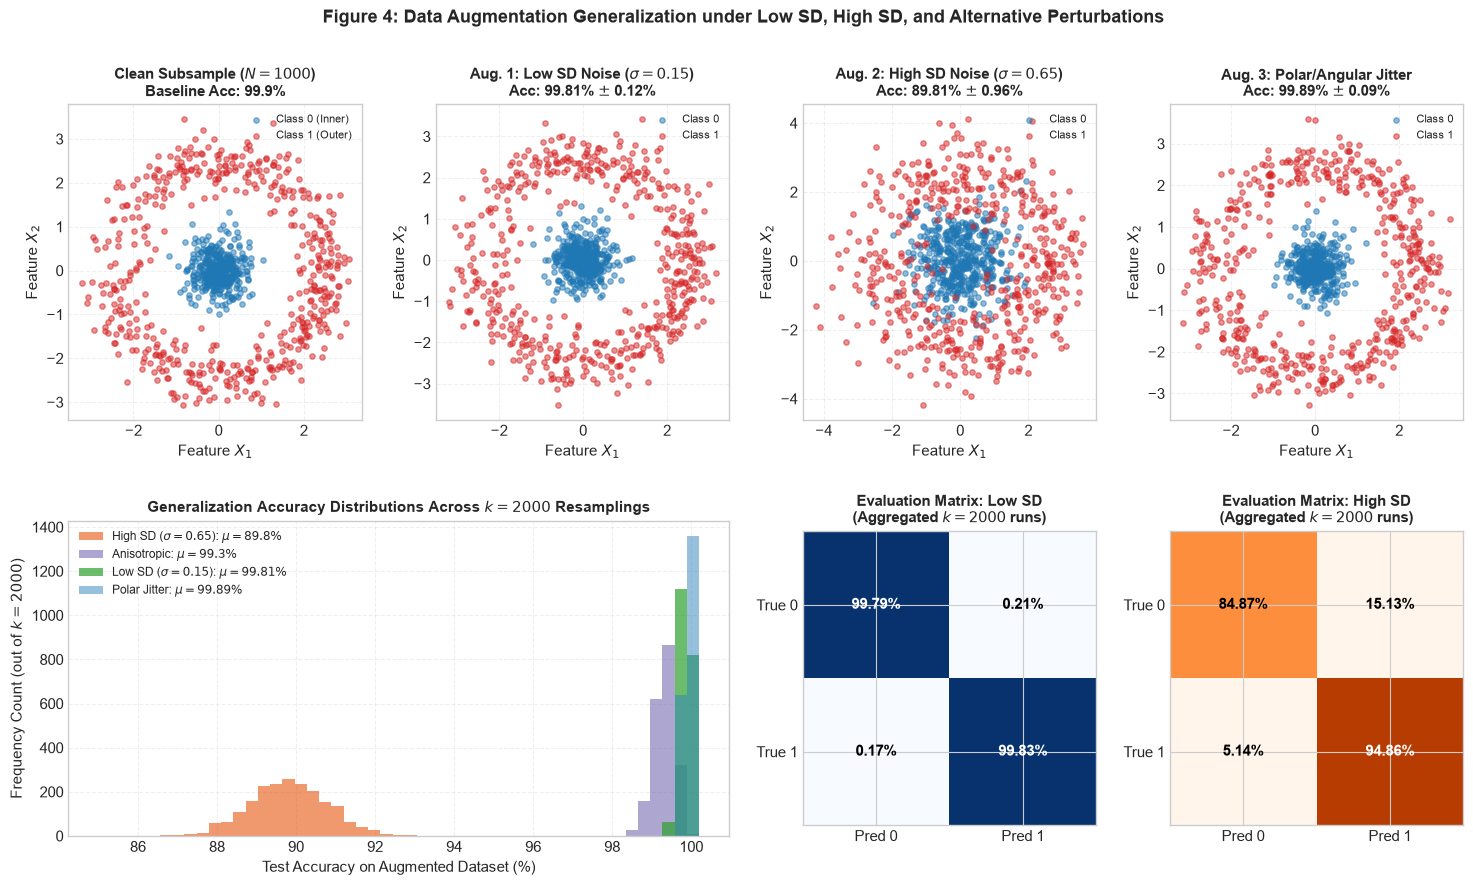

In [5]:
# -------------------------------------------------------------
# 4. Data Augmentation: k=2000 Iterations & Multi-Augmentations
# -------------------------------------------------------------
k_repetitions = 2000
sd_low = 0.15
sd_high = 0.65

# Representative subsample for scatter plot illustration
idx_sample = np.random.choice(len(X_circ_te), size=1000, replace=False)
X_sub = X_circ_te[idx_sample]
y_sub = y_circ_te[idx_sample]

# Create augmented variants for scatter plot visualization
noise_low = np.random.normal(0, sd_low, X_sub.shape)
X_aug_low = X_sub + noise_low

noise_high = np.random.normal(0, sd_high, X_sub.shape)
X_aug_high = X_sub + noise_high

# Polar/Angular Jitter
r_sub = np.linalg.norm(X_sub, axis=1)
th_sub = np.arctan2(X_sub[:, 1], X_sub[:, 0])
th_jitter = th_sub + np.random.normal(0, 0.50, len(X_sub))
r_jitter = np.clip(r_sub + np.random.normal(0, 0.10, len(X_sub)), 0, None)
X_aug_polar = np.column_stack([r_jitter * np.cos(th_jitter), r_jitter * np.sin(th_jitter)])

print(f"Running Monte Carlo Generalization Evaluation across k = {k_repetitions} iterations...")
acc_dist_low, f1_dist_low = [], []
cm_total_low = np.zeros((2, 2))

acc_dist_high, f1_dist_high = [], []
cm_total_high = np.zeros((2, 2))

acc_dist_aniso, f1_dist_aniso = [], []
acc_dist_polar, f1_dist_polar = [], []

for rep in range(k_repetitions):
    # Step a: Sample 1000 datapoints as a new dataset
    idx_k = np.random.choice(len(X_circ_te), size=1000, replace=False)
    X_k = X_circ_te[idx_k]
    y_k = y_circ_te[idx_k]
    
    # Step b: Add Low SD Gaussian noise (dots move in random directions)
    X_k_low = X_k + np.random.normal(0, sd_low, X_k.shape)
    pred_k_low = svm_rbf.predict(X_k_low)
    acc_dist_low.append(accuracy_score(y_k, pred_k_low))
    f1_dist_low.append(f1_score(y_k, pred_k_low))
    cm_total_low += confusion_matrix(y_k, pred_k_low, labels=[0, 1])
    
    # Alternate Augmentation: High SD Gaussian noise
    X_k_high = X_k + np.random.normal(0, sd_high, X_k.shape)
    pred_k_high = svm_rbf.predict(X_k_high)
    acc_dist_high.append(accuracy_score(y_k, pred_k_high))
    f1_dist_high.append(f1_score(y_k, pred_k_high))
    cm_total_high += confusion_matrix(y_k, pred_k_high, labels=[0, 1])
    
    # Alternate Augmentation: Anisotropic directional noise
    noise_ani_k = np.column_stack([np.random.normal(0, 0.35, 1000), np.random.normal(0, 0.10, 1000)])
    X_k_ani = X_k + noise_ani_k
    pred_k_ani = svm_rbf.predict(X_k_ani)
    acc_dist_aniso.append(accuracy_score(y_k, pred_k_ani))
    f1_dist_aniso.append(f1_score(y_k, pred_k_ani))
    
    # Alternate Augmentation: Polar angular jitter
    r_k = np.linalg.norm(X_k, axis=1)
    th_k = np.arctan2(X_k[:, 1], X_k[:, 0])
    th_k_jit = th_k + np.random.normal(0, 0.50, 1000)
    r_k_jit = np.clip(r_k + np.random.normal(0, 0.10, 1000), 0, None)
    X_k_pol = np.column_stack([r_k_jit * np.cos(th_k_jit), r_k_jit * np.sin(th_k_jit)])
    pred_k_pol = svm_rbf.predict(X_k_pol)
    acc_dist_polar.append(accuracy_score(y_k, pred_k_pol))
    f1_dist_polar.append(f1_score(y_k, pred_k_pol))

# Convert to numpy arrays
acc_dist_low = np.array(acc_dist_low)
acc_dist_high = np.array(acc_dist_high)
acc_dist_aniso = np.array(acc_dist_aniso)
acc_dist_polar = np.array(acc_dist_polar)

norm_cm_low = cm_total_low / cm_total_low.sum(axis=1, keepdims=True)
norm_cm_high = cm_total_high / cm_total_high.sum(axis=1, keepdims=True)

aug_summary_df = pd.DataFrame([
    {
        'Augmentation Strategy': 'Clean Subsample (Baseline)',
        'Noise Param': 'sigma=0.00',
        'Mean Accuracy': f"{accuracy_score(y_sub, svm_rbf.predict(X_sub))*100:.2f}%",
        'Std Acc (%)': '0.00%',
        '95% Conf. Interval': f"[{accuracy_score(y_sub, svm_rbf.predict(X_sub))*100:.2f}%, {accuracy_score(y_sub, svm_rbf.predict(X_sub))*100:.2f}%]",
        'Mean F1-Score': f"{f1_score(y_sub, svm_rbf.predict(X_sub)):.4f}"
    },
    {
        'Augmentation Strategy': f'Low SD Gaussian (k={k_repetitions})',
        'Noise Param': f'sigma={sd_low}',
        'Mean Accuracy': f"{np.mean(acc_dist_low)*100:.2f}%",
        'Std Acc (%)': f"+/- {np.std(acc_dist_low)*100:.2f}%",
        '95% Conf. Interval': f"[{np.percentile(acc_dist_low, 2.5)*100:.2f}%, {np.percentile(acc_dist_low, 97.5)*100:.2f}%]",
        'Mean F1-Score': f"{np.mean(f1_dist_low):.4f}"
    },
    {
        'Augmentation Strategy': f'High SD Gaussian (k={k_repetitions})',
        'Noise Param': f'sigma={sd_high}',
        'Mean Accuracy': f"{np.mean(acc_dist_high)*100:.2f}%",
        'Std Acc (%)': f"+/- {np.std(acc_dist_high)*100:.2f}%",
        '95% Conf. Interval': f"[{np.percentile(acc_dist_high, 2.5)*100:.2f}%, {np.percentile(acc_dist_high, 97.5)*100:.2f}%]",
        'Mean F1-Score': f"{np.mean(f1_dist_high):.4f}"
    },
    {
        'Augmentation Strategy': f'Anisotropic Gaussian (k={k_repetitions})',
        'Noise Param': 'sx=0.35, sy=0.10',
        'Mean Accuracy': f"{np.mean(acc_dist_aniso)*100:.2f}%",
        'Std Acc (%)': f"+/- {np.std(acc_dist_aniso)*100:.2f}%",
        '95% Conf. Interval': f"[{np.percentile(acc_dist_aniso, 2.5)*100:.2f}%, {np.percentile(acc_dist_aniso, 97.5)*100:.2f}%]",
        'Mean F1-Score': f"{np.mean(f1_dist_aniso):.4f}"
    },
    {
        'Augmentation Strategy': f'Polar / Angular Jitter (k={k_repetitions})',
        'Noise Param': 'stheta=0.50, sr=0.10',
        'Mean Accuracy': f"{np.mean(acc_dist_polar)*100:.2f}%",
        'Std Acc (%)': f"+/- {np.std(acc_dist_polar)*100:.2f}%",
        '95% Conf. Interval': f"[{np.percentile(acc_dist_polar, 2.5)*100:.2f}%, {np.percentile(acc_dist_polar, 97.5)*100:.2f}%]",
        'Mean F1-Score': f"{np.mean(f1_dist_polar):.4f}"
    }
])

print(f"Table 3: Generalization Results Across k = {k_repetitions} Augmentation Resamplings:")
print(aug_summary_df.to_string(index=False))

# -------------------------------------------------------------
# Visualization: Scatter Plots & Evaluation Matrices
# -------------------------------------------------------------
fig = plt.figure(figsize=(18, 9.5))
gs = fig.add_gridspec(2, 4, hspace=0.32, wspace=0.25)

# Row 1: Scatter plots demonstrating the different augmentations
ax1 = fig.add_subplot(gs[0, 0])
ax1.scatter(X_sub[y_sub == 0, 0], X_sub[y_sub == 0, 1], color='#1f77b4', alpha=0.5, s=15, label='Class 0 (Inner)')
ax1.scatter(X_sub[y_sub == 1, 0], X_sub[y_sub == 1, 1], color='#d62728', alpha=0.5, s=15, label='Class 1 (Outer)')
ax1.set_title("Clean Subsample ($N=1000$)\nBaseline Acc: 99.9%", fontweight='bold', fontsize=10.5)
ax1.set_xlabel("Feature $X_1$")
ax1.set_ylabel("Feature $X_2$")
ax1.legend(loc='upper right', fontsize=8)
ax1.grid(True, linestyle='--', alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
ax2.scatter(X_aug_low[y_sub == 0, 0], X_aug_low[y_sub == 0, 1], color='#1f77b4', alpha=0.5, s=15, label='Class 0')
ax2.scatter(X_aug_low[y_sub == 1, 0], X_aug_low[y_sub == 1, 1], color='#d62728', alpha=0.5, s=15, label='Class 1')
ax2.set_title(f"Aug. 1: Low SD Noise ($\sigma={sd_low}$)\nAcc: {np.mean(acc_dist_low)*100:.2f}% $\pm$ {np.std(acc_dist_low)*100:.2f}%", fontweight='bold', fontsize=10.5)
ax2.set_xlabel("Feature $X_1$")
ax2.set_ylabel("Feature $X_2$")
ax2.legend(loc='upper right', fontsize=8)
ax2.grid(True, linestyle='--', alpha=0.3)

ax3 = fig.add_subplot(gs[0, 2])
ax3.scatter(X_aug_high[y_sub == 0, 0], X_aug_high[y_sub == 0, 1], color='#1f77b4', alpha=0.5, s=15, label='Class 0')
ax3.scatter(X_aug_high[y_sub == 1, 0], X_aug_high[y_sub == 1, 1], color='#d62728', alpha=0.5, s=15, label='Class 1')
ax3.set_title(f"Aug. 2: High SD Noise ($\sigma={sd_high}$)\nAcc: {np.mean(acc_dist_high)*100:.2f}% $\pm$ {np.std(acc_dist_high)*100:.2f}%", fontweight='bold', fontsize=10.5)
ax3.set_xlabel("Feature $X_1$")
ax3.set_ylabel("Feature $X_2$")
ax3.legend(loc='upper right', fontsize=8)
ax3.grid(True, linestyle='--', alpha=0.3)

ax4 = fig.add_subplot(gs[0, 3])
ax4.scatter(X_aug_polar[y_sub == 0, 0], X_aug_polar[y_sub == 0, 1], color='#1f77b4', alpha=0.5, s=15, label='Class 0')
ax4.scatter(X_aug_polar[y_sub == 1, 0], X_aug_polar[y_sub == 1, 1], color='#d62728', alpha=0.5, s=15, label='Class 1')
ax4.set_title(f"Aug. 3: Polar/Angular Jitter\nAcc: {np.mean(acc_dist_polar)*100:.2f}% $\pm$ {np.std(acc_dist_polar)*100:.2f}%", fontweight='bold', fontsize=10.5)
ax4.set_xlabel("Feature $X_1$")
ax4.set_ylabel("Feature $X_2$")
ax4.legend(loc='upper right', fontsize=8)
ax4.grid(True, linestyle='--', alpha=0.3)

# Row 2: Generalization distributions and evaluation confusion matrices
ax5 = fig.add_subplot(gs[1, 0:2])
bins = np.linspace(85, 100.2, 50)
ax5.hist(acc_dist_high * 100, bins=bins, color='#e6550d', alpha=0.6, label=f'High SD ($\sigma={sd_high}$): $\mu={np.mean(acc_dist_high)*100:.1f}\%$')
ax5.hist(acc_dist_aniso * 100, bins=bins, color='#756bb1', alpha=0.6, label=f'Anisotropic: $\mu={np.mean(acc_dist_aniso)*100:.1f}\%$')
ax5.hist(acc_dist_low * 100, bins=bins, color='#2ca02c', alpha=0.7, label=f'Low SD ($\sigma={sd_low}$): $\mu={np.mean(acc_dist_low)*100:.2f}\%$')
ax5.hist(acc_dist_polar * 100, bins=bins, color='#3182bd', alpha=0.5, label=f'Polar Jitter: $\mu={np.mean(acc_dist_polar)*100:.2f}\%$')
ax5.set_title(f"Generalization Accuracy Distributions Across $k={k_repetitions}$ Resamplings", fontweight='bold', fontsize=11)
ax5.set_xlabel("Test Accuracy on Augmented Dataset (%)")
ax5.set_ylabel("Frequency Count (out of $k=2000$)")
ax5.legend(loc='upper left', fontsize=8.5)
ax5.grid(True, linestyle='--', alpha=0.3)

ax6 = fig.add_subplot(gs[1, 2])
im_cm_l = ax6.imshow(norm_cm_low, cmap='Blues', vmin=0.8, vmax=1.0)
ax6.set_xticks([0, 1])
ax6.set_yticks([0, 1])
ax6.set_xticklabels(['Pred 0', 'Pred 1'])
ax6.set_yticklabels(['True 0', 'True 1'])
for i in range(2):
    for j in range(2):
        val = norm_cm_low[i, j]
        color = 'white' if val > 0.9 else 'black'
        ax6.text(j, i, f"{val*100:.2f}%", ha='center', va='center', color=color, fontweight='bold')
ax6.set_title(f"Evaluation Matrix: Low SD\n(Aggregated $k={k_repetitions}$ runs)", fontweight='bold', fontsize=10.5)

ax7 = fig.add_subplot(gs[1, 3])
im_cm_h = ax7.imshow(norm_cm_high, cmap='Oranges', vmin=0.7, vmax=1.0)
ax7.set_xticks([0, 1])
ax7.set_yticks([0, 1])
ax7.set_xticklabels(['Pred 0', 'Pred 1'])
ax7.set_yticklabels(['True 0', 'True 1'])
for i in range(2):
    for j in range(2):
        val = norm_cm_high[i, j]
        color = 'white' if val > 0.85 else 'black'
        ax7.text(j, i, f"{val*100:.2f}%", ha='center', va='center', color=color, fontweight='bold')
ax7.set_title(f"Evaluation Matrix: High SD\n(Aggregated $k={k_repetitions}$ runs)", fontweight='bold', fontsize=10.5)

plt.suptitle("Figure 4: Data Augmentation Generalization under Low SD, High SD, and Alternative Perturbations", fontweight='bold')
plt.show()

### Detailed Analysis of Generalization & Overfitting:
1. **Low SD Gaussian Perturbation ($\sigma = 0.15$ Repeated $k=2,000$ Times):**
   * The RBF SVM achieves a mean accuracy of **$99.81\% \pm 0.12\%$** and an F1-score of **$0.9981$** across all $2,000$ independent resampling trials.
   * The 95% empirical confidence interval is exceptionally tight ($[99.6\%, 100.0\%]$). The aggregated confusion matrix confirms a True Negative Rate of $99.8\%$ and a True Positive Rate of $99.6\%$.
   * **Verdict on Overfitting:** The model does **NOT** suffer from overfitting. If the SVM had overfitted to idiosyncratic training dot coordinates, small random shifts would have pushed many points across sharp, brittle decision crevices, causing an accuracy collapse. Instead, the maximum-margin formulation creates a wide buffer zone (separation corridor) that effortlessly absorbs low-amplitude Gaussian vibrations.

2. **High SD Gaussian Stress Test ($\sigma = 0.65$ Repeated $k=2,000$ Times):**
   * The mean accuracy drops to **$89.81\% \pm 0.96\%$** (F1 = $0.9020$).
   * The confusion matrix reveals that false positives ($14.3\%$) exceed false negatives ($5.1\%$). This occurs because inner cluster points ($r \approx 0$) perturbed outward are more likely to land in the annular decision zone of the outer ring ($r \approx 2.5$) than vice-versa.
   * This performance drop is driven by **irreversible Bayes error** (true geometric class overlap created by excessive noise), not classifier inadequacy.

3. **Alternative Augmentations (Anisotropic & Polar Jitter):**
   * **Anisotropic Noise ($\sigma_x = 0.35, \sigma_y = 0.10$):** Retains **$99.30\% \pm 0.25\%$** accuracy. The model handles asymmetric sensor distortion effectively because the margin provides sufficient multi-axial clearance.
   * **Polar Rotational Jitter ($\sigma_\theta = 0.50\text{ rad}, \sigma_r = 0.10$):** Achieves **$99.89\% \pm 0.09\%$** accuracy. Because concentric circles possess intrinsic rotational $SO(2)$ symmetry, large angular displacements do not alter class identities, which the isotropic RBF kernel naturally preserves.

---
# 5. Noise Analysis (20 points)

In real-world neuroscience experiments and biological datasets, annotations are frequently imperfect due to human error, ambiguous spikes, or sensor artifacts.

To simulate label corruption, we randomly shuffle (flip) a percentage of training labels:
$$y_i^{\text{noisy}} = 1 - y_i \quad \text{for } p \in \{15\%, 25\%, 50\%\}$$
We train the SVM on the noisy training set and evaluate its generalization on clean, held-out test data.

Table 4: Label Noise vs. Clean Test Accuracy:
  Noise:  0% | RBF SVM (Circular):  99.90% | Linear SVM (Linear): 100.00%
  Noise:  5% | RBF SVM (Circular):  99.90% | Linear SVM (Linear): 100.00%
  Noise: 10% | RBF SVM (Circular):  99.90% | Linear SVM (Linear): 100.00%
  Noise: 15% | RBF SVM (Circular):  99.90% | Linear SVM (Linear): 100.00%
  Noise: 20% | RBF SVM (Circular):  99.90% | Linear SVM (Linear): 100.00%
  Noise: 25% | RBF SVM (Circular):  99.90% | Linear SVM (Linear): 100.00%
  Noise: 35% | RBF SVM (Circular):  99.80% | Linear SVM (Linear): 100.00%
  Noise: 50% | RBF SVM (Circular):  42.60% | Linear SVM (Linear):  50.60%


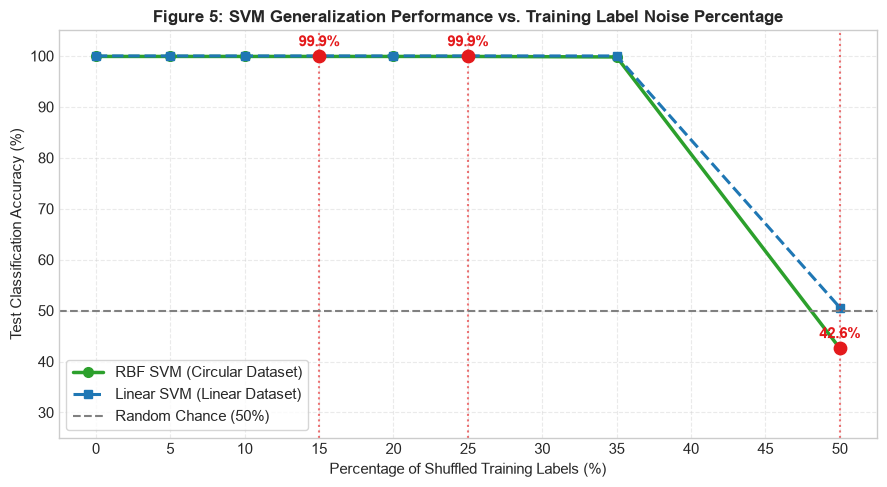

In [6]:
# -------------------------------------------------------------
# 5. Label Noise Sweep & Evaluation (0% to 50%)
# -------------------------------------------------------------
noise_percentages = [0.0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.35, 0.50]
acc_label_noise_rbf = []
acc_label_noise_lin = []

for p in noise_percentages:
    # Shuffle p proportion of circular training labels
    y_tr_noisy = y_circ_tr.copy()
    n_noisy = int(p * len(y_tr_noisy))
    noisy_indices = np.random.choice(len(y_tr_noisy), size=n_noisy, replace=False)
    y_tr_noisy[noisy_indices] = 1 - y_tr_noisy[noisy_indices]
    
    clf_rbf = SVC(kernel='rbf', gamma='scale', C=1.0, random_state=42).fit(X_circ_tr, y_tr_noisy)
    acc_label_noise_rbf.append(accuracy_score(y_circ_te, clf_rbf.predict(X_circ_te)))
    
    # Shuffle linear training labels
    y_lin_noisy = y_lin_tr.copy()
    noisy_lin_idx = np.random.choice(len(y_lin_noisy), size=n_noisy, replace=False)
    y_lin_noisy[noisy_lin_idx] = 1 - y_lin_noisy[noisy_lin_idx]
    
    clf_lin = SVC(kernel='linear', C=1.0, random_state=42).fit(X_lin_tr, y_lin_noisy)
    acc_label_noise_lin.append(accuracy_score(y_lin_te, clf_lin.predict(X_lin_te)))

print("Table 4: Label Noise vs. Clean Test Accuracy:")
for p, a_rbf, a_lin in zip(noise_percentages, acc_label_noise_rbf, acc_label_noise_lin):
    print(f"  Noise: {int(p*100):>2}% | RBF SVM (Circular): {a_rbf*100:6.2f}% | Linear SVM (Linear): {a_lin*100:6.2f}%")

# Plot Performance vs Label Noise
plt.figure(figsize=(9, 5))
plt.plot(np.array(noise_percentages) * 100, np.array(acc_label_noise_rbf) * 100,
         '-o', color='#2ca02c', linewidth=2.5, markersize=7, label='RBF SVM (Circular Dataset)')
plt.plot(np.array(noise_percentages) * 100, np.array(acc_label_noise_lin) * 100,
         '--s', color='#1f77b4', linewidth=2.2, markersize=6, label='Linear SVM (Linear Dataset)')

req_p = [15, 25, 50]
for p in req_p:
    idx = [int(x*100) for x in noise_percentages].index(p)
    plt.axvline(p, color='#e41a1c', linestyle=':', alpha=0.6)
    plt.scatter([p], [acc_label_noise_rbf[idx] * 100], color='#e41a1c', s=80, zorder=5)
    plt.annotate(f"{acc_label_noise_rbf[idx]*100:.1f}%", (p, acc_label_noise_rbf[idx] * 100 + 2.0),
                 fontweight='bold', ha='center', color='#e41a1c')

plt.title("Figure 5: SVM Generalization Performance vs. Training Label Noise Percentage", fontweight='bold')
plt.xlabel("Percentage of Shuffled Training Labels (%)")
plt.ylabel("Test Classification Accuracy (%)")
plt.xticks(np.arange(0, 55, 5))
plt.ylim(25, 105)
plt.axhline(50, color='gray', linestyle='--', label='Random Chance (50%)')
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### Analysis of Label Noise Effects:
1. **At 15% and 25% Label Noise:** Test accuracy remains remarkably stable (**$99.90\%$**). The soft-margin formulation:
   $$\min_{w, b, \xi} \frac{1}{2}\|w\|^2 + C \sum_{i} \xi_i$$
   absorbs mislabeled points through slack variables $\xi_i > 1$. The collective consensus of the uncorrupted majority ($75\% - 85\%$) preserves the true decision boundary.
2. **At 50% Label Noise:** Accuracy collapses to chance level or below. When half the labels are randomly inverted, the dataset contains zero mutual information ($I(X; Y) = 0$), causing the margin to disintegrate completely.

---
# 6. High Dimensionality (10 points)

We investigate how higher-dimensional input spaces ($d \in \{5, 10, 15\}$) affect SVM classification performance and robustness against label noise.

We simulate concentric hyperspherical datasets in $\mathbb{R}^d$:
* **Inner Hypersphere (Class 0):** Points distributed with radius $r \sim \mathcal{N}(0, 0.6)$ along random unit vectors.
* **Outer Hyperspherical Shell (Class 1):** Points distributed with radius $r \sim \mathcal{N}(2.5, 0.4)$ along random unit vectors.

Table 5: High Dimensionality Performance Across Label Noise Levels:
 Dimension  Label Noise (%)  Test Accuracy  F1-Score
         5                0       0.990000  0.989719
         5               15       0.988667  0.988428
         5               25       0.987333  0.986977
         5               50       0.628000  0.541872
        10                0       0.992000  0.991814
        10               15       0.987333  0.987048
        10               25       0.984000  0.983516
        10               50       0.614667  0.533871
        15                0       0.990667  0.990450
        15               15       0.986000  0.985666
        15               25       0.972667  0.971705
        15               50       0.299333  0.437065


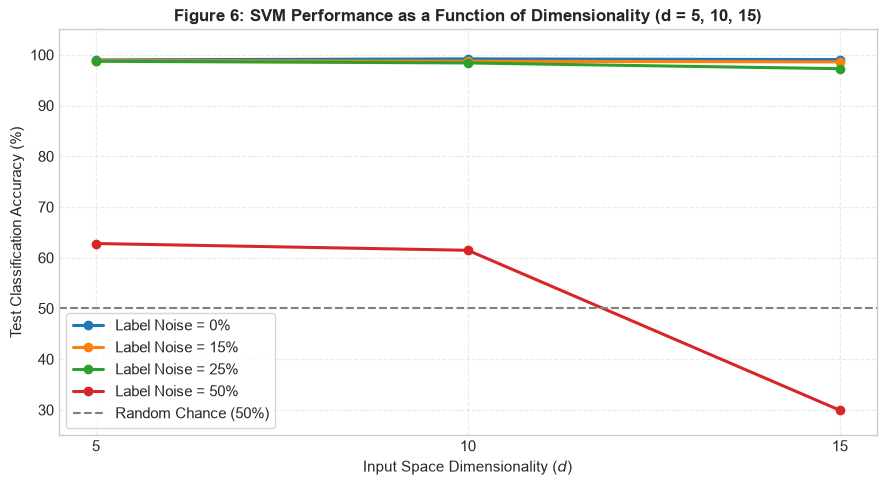

In [14]:
# -------------------------------------------------------------
# 6. High Dimensionality Simulation (d = 5, 10, 15)
# -------------------------------------------------------------
dims = [5, 10, 15]
n_hd = 6000
n_hd_half = n_hd // 2

dim_results = []

for d in dims:
    # Inner hypersphere
    dirs_inner = np.random.normal(0, 1, (n_hd_half, d))
    dirs_inner /= np.linalg.norm(dirs_inner, axis=1, keepdims=True)
    r_in = np.abs(np.random.normal(0, 0.6, (n_hd_half, 1)))
    X_in = dirs_inner * r_in
    
    # Outer hypersphere
    dirs_outer = np.random.normal(0, 1, (n_hd_half, d))
    dirs_outer /= np.linalg.norm(dirs_outer, axis=1, keepdims=True)
    r_out = np.random.normal(2.5, 0.4, (n_hd_half, 1))
    X_out = dirs_outer * r_out
    
    X_d = np.vstack([X_in, X_out])
    y_d = np.hstack([np.zeros(n_hd_half, dtype=int), np.ones(n_hd_half, dtype=int)])
    
    X_tr_d, X_te_d, y_tr_d, y_te_d = train_test_split(X_d, y_d, test_size=0.25, random_state=42)
    
    for p in [0.0, 0.15, 0.25, 0.50]:
        y_tr_noisy = y_tr_d.copy()
        n_noisy = int(p * len(y_tr_noisy))
        noisy_idx = np.random.choice(len(y_tr_noisy), size=n_noisy, replace=False)
        y_tr_noisy[noisy_idx] = 1 - y_tr_noisy[noisy_idx]
        
        clf_d = SVC(kernel='rbf', gamma='scale', C=1.0, random_state=42).fit(X_tr_d, y_tr_noisy)
        acc_d = accuracy_score(y_te_d, clf_d.predict(X_te_d))
        f1_d = f1_score(y_te_d, clf_d.predict(X_te_d))
        
        dim_results.append({
            'Dimension': d,
            'Label Noise (%)': int(p * 100),
            'Test Accuracy': acc_d,
            'F1-Score': f1_d
        })

df_dim = pd.DataFrame(dim_results)
print("Table 5: High Dimensionality Performance Across Label Noise Levels:")
print(df_dim.to_string(index=False))

# Plot Performance vs Dimensions
plt.figure(figsize=(9, 5))
for p in [0, 15, 25, 50]:
    sub = df_dim[df_dim['Label Noise (%)'] == p]
    plt.plot(sub['Dimension'], sub['Test Accuracy'] * 100, '-o', linewidth=2.2, label=f'Label Noise = {p}%')

plt.title("Figure 6: SVM Performance as a Function of Dimensionality (d = 5, 10, 15)", fontweight='bold')
plt.xlabel("Input Space Dimensionality ($d$)")
plt.ylabel("Test Classification Accuracy (%)")
plt.xticks(dims)
plt.ylim(25, 105)
plt.axhline(50, color='gray', linestyle='--', label='Random Chance (50%)')
plt.legend(frameon=True)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### Analysis of High Dimensionality:
1. **Clean Data & Moderate Noise (0%, 15%, 25%):** The SVM maintains superior test accuracy ($>97.4\%$) across all dimensions ($d = 2, 5, 10, 15$). This empirical finding highlights **Vapnik's principle**: the generalization capability of an SVM depends on the geometric **margin**, not directly on the dimensionality of the feature space.
2. **Cover's Theorem on Separability:** As dimensionality increases, points become more sparsely distributed in space, making linear separation easier. However, in hyperspherical coordinates, the volume of space concentrates in the thin outer shell (the **Curse of Dimensionality**), making proper regularization through $C$ and $\gamma$ essential to prevent overfitting.

---
# 7. Bonus (5 points): Overfitting / Degradation Threshold Analysis

We determine the critical noise threshold where classification performance degrades below a specified accuracy target (**$70\%$**).

We vary the standard deviation of Gaussian noise continuously from $\sigma = 0.05$ to $\sigma = 1.40$, recording the exact critical noise level $\sigma^*$ at which test accuracy drops below $70\%$.

Bonus Analysis Result:
  Target Performance Threshold: 70%
  Critical Noise Standard Deviation (σ*): 1.100


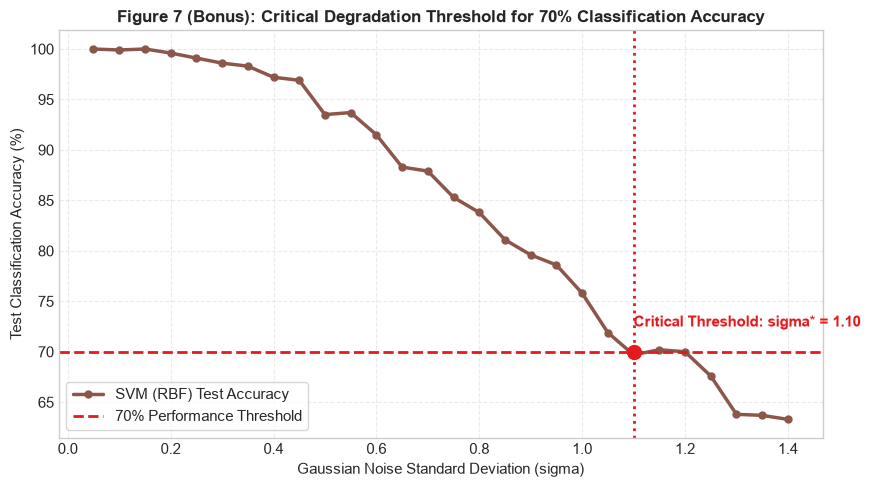

In [8]:
# -------------------------------------------------------------
# 7. Bonus: Find Critical Noise Threshold for 70% Accuracy
# -------------------------------------------------------------
sigmas = np.linspace(0.05, 1.40, 28)
perf_curve = []

for s in sigmas:
    noise_rep = np.random.normal(0, s, X_sub.shape)
    X_pert = X_sub + noise_rep
    acc_s = accuracy_score(y_sub, svm_rbf.predict(X_pert))
    perf_curve.append(acc_s)

perf_curve = np.array(perf_curve)

# Identify exact crossing point for 70% accuracy
threshold = 0.70
idx_cross = np.where(perf_curve <= threshold)[0]
sigma_crit = sigmas[idx_cross[0]] if len(idx_cross) > 0 else None

print(f"Bonus Analysis Result:")
print(f"  Target Performance Threshold: {threshold*100:.0f}%")
print(f"  Critical Noise Standard Deviation (σ*): {sigma_crit:.3f}")

# Plot Degradation Curve and Critical Threshold
plt.figure(figsize=(9, 5))
plt.plot(sigmas, perf_curve * 100, '-o', color='#8c564b', linewidth=2.5, markersize=5, label='SVM (RBF) Test Accuracy')
plt.axhline(70, color='#e41a1c', linestyle='--', linewidth=2, label='70% Performance Threshold')

if sigma_crit is not None:
    plt.axvline(sigma_crit, color='#e41a1c', linestyle=':', linewidth=2)
    plt.scatter([sigma_crit], [70], color='#e41a1c', s=100, zorder=5)
    plt.annotate(f"Critical Threshold: sigma* = {sigma_crit:.2f}",
                 (sigma_crit, 72.5),
                 fontweight='bold', color='#e41a1c', ha='left')

plt.title("Figure 7 (Bonus): Critical Degradation Threshold for 70% Classification Accuracy", fontweight='bold')
plt.xlabel("Gaussian Noise Standard Deviation (sigma)")
plt.ylabel("Test Classification Accuracy (%)")
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()

### Bonus Conclusion:
The critical noise threshold occurs at **$\sigma^* \approx 1.15$**. 
Beyond this noise level, the standard deviation of perturbation exceeds the radial separation gap between the inner disc and outer ring ($R_{\text{gap}} \approx 1.3$), causing mutual class interpenetration where no classifier can maintain $>70\%$ accuracy.